<center>
<h style="line-height: 0.5;">

# Applying Machine Learning to Gravitational Lens Modeling
#### **Research Advisor**: Professor Charles Keeton
#### **Research Assistant**: Satyajit Gade

</h>
</center>

In [1]:
# imports all the modules needed
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import emcee
import corner
import arviz
from scipy import stats
import sys
import os
sys.path.append(os.path.join(os.getcwd(), '..', 'scripts'))
import pygravlens as gl
from astropy.cosmology import Planck18 as cosmo
from matplotlib.patches import Arc
from pathlib import Path 

In [2]:
# Get the repo root directory (one level up from Notebooks)
repo_root = Path.cwd().parent
data_path = repo_root / 'combined_arrays'

scripts_path = repo_root / 'scripts'

sys.path.append(str(scripts_path))

### Shear Only

In [3]:
vals_shear = np.load(data_path / 'valShear.npy', allow_pickle=True)

In [4]:
# printing out specificed dictionary values for img, magnification, and time-delay arrays
'''
for i in range(len(vals_shear)):
    print('Here is the image array: \n', vals_shear[i]["img"], '\n')
    print('Here is the magnification array: \n', vals_shear[i]["mu"], '\n')
    print('Here is the time delay array: \n', vals_shear[i]["time"], '\n')
    ---
    print('Here is the ellip_c array: \n', values[i]["ellipc"], '\n')
    print('Here is the ellip_s array: \n', values[i]["ellips"], '\n')
    print('Here is the gamma_c array: \n', values[i]["gammc"], '\n')
    print('Here is the gamma_s array: \n', values[i]["gamms"], '\n')
    print()
    ---
    print('----------------------------Next Mock Lens----------------------------')
'''    
# note that the values dictionary contains i elements where i represents the number of mock lenses

# now we define a separate dictionary containing keys as "single," "double," or "quad" 
# with values as the index of the mock lens for single, double, and quad lenses respectively

single = [];
double = [];
quad = [];

weirdCase = []
for i in range(len(vals_shear)):
    size = len(vals_shear[i]["img"]);
    neither = {}
    if size == 4:
        quad.append(i)
    elif size == 2:
        double.append(i)
    elif size == 1:
        single.append(i)
    else:
        neither = dict(index = i, size = size)
    weirdCase.append(neither)

typeLens = dict(single = single, double = double, quad = quad)


### ========Hiding Print Statement to Make Notebook Readable======== ###

'''
print("The index array for a single image producing mock lens is: ", typeLens["single"],'\n')
print("The index array for a double image producing mock lens is: ", typeLens["double"],'\n')
print("The index array for a quad image producing mock lens is: ", typeLens["quad"],'\n')

for j in weirdCase:
    sz = len(j)
    if sz != 0:
        print("The index for neither single, double, or quad is: ", j["index"],'\n')
        print("And the images produced by this lens are: ", j["size"],'\n')
        print('----------------------------Next Non Single, Double, or Quad Mock Lens----------------------------')''';

### Ellipticity Only

In [5]:
vals_ellip = np.load(data_path / 'valEllip.npy', allow_pickle = True)

In [6]:
# printing out specificed dictionary values for img, magnification, and time-delay arrays

'''
for i in range(len(vals_ellip)):
    print('Here is the image array: \n', vals_ellip[i]["img"], '\n')
    print('Here is the magnification array: \n', vals_ellip[i]["mu"], '\n')
    print('Here is the time delay array: \n', vals_ellip[i]["time"], '\n')
    --
    print('Here is the ellip_c array: \n', values[i]["ellipc"], '\n')
    print('Here is the ellip_s array: \n', values[i]["ellips"], '\n')
    print('Here is the gamma_c array: \n', values[i]["gammc"], '\n')
    print('Here is the gamma_s array: \n', values[i]["gamms"], '\n')
    print()
    ---
    print('----------------------------Next Mock Lens----------------------------')
'''
    
# note that the values dictionary contains i elements where i represents the number of mock lenses

# now we define a separate dictionary containing keys as "single," "double," or "quad" 
# with values as the index of the mock lens for single, double, and quad lenses respectively

single = [];
double = [];
quad = [];

weirdCase_ellip = []
for i in range(len(vals_ellip)):
    size = len(vals_ellip[i]["img"]);
    neither = {}
    if size == 4:
        quad.append(i)
    elif size == 2:
        double.append(i)
    elif size == 1:
        single.append(i)
    else:
        neither = dict(index = i, size = size)
    weirdCase_ellip.append(neither)

typeLens_ellip = dict(single = single, double = double, quad = quad)

### ========Hiding Print Statement to Make Notebook Readable======== ###
'''
print("The index array for a single image producing mock lens is: ", typeLens_ellip["single"],'\n')
print("The index array for a double image producing mock lens is: ", typeLens_ellip["double"],'\n')
print("The index array for a quad image producing mock lens is: ", typeLens_ellip["quad"],'\n')

for j in weirdCase_ellip:
    sz = len(j)
    if sz != 0:
        print("The index for neither single, double, or quad is: ", j["index"],'\n')
        print("And the images produced by this lens are: ", j["size"],'\n')
        print('----------------------------Next Non Single, Double, or Quad Mock Lens----------------------------')''';

### Ellipticity & Shear

In [7]:
vals_both = np.load(data_path / 'valBoth.npy', allow_pickle = True)

In [8]:
# printing out specificed dictionary values for img, magnification, and time-delay arrays
'''
for i in range(len(vals_both)):
    print('Here is the image array: \n', vals_both[i]["img"], '\n')
    print('Here is the magnification array: \n', vals_both[i]["mu"], '\n')
    print('Here is the time delay array: \n', vals_both[i]["time"], '\n')
    ---
    print('Here is the ellip_c array: \n', values[i]["ellipc"], '\n')
    print('Here is the ellip_s array: \n', values[i]["ellips"], '\n')
    print('Here is the gamma_c array: \n', values[i]["gammc"], '\n')
    print('Here is the gamma_s array: \n', values[i]["gamms"], '\n')
    print()
    ---
    print('----------------------------Next Mock Lens----------------------------')
'''    
# note that the values dictionary contains i elements where i represents the number of mock lenses

# now we define a separate dictionary containing keys as "single," "double," or "quad" 
# with values as the index of the mock lens for single, double, and quad lenses respectively

single = [];
double = [];
quad = [];

weirdCase_both = []
for i in range(len(vals_both)):
    size = len(vals_both[i]["img"]);
    neither = {}
    if size == 4:
        quad.append(i)
    elif size == 2:
        double.append(i)
    elif size == 1:
        single.append(i)
    else:
        neither = dict(index = i, size = size)
    weirdCase_both.append(neither)

typeLens_both = dict(single = single, double = double, quad = quad)


### ========Hiding Print Statement to Make Notebook Readable======== ###
'''
print("The index array for a single image producing mock lens is: ", typeLens_both["single"],'\n')
print("The index array for a double image producing mock lens is: ", typeLens_both["double"],'\n')
print("The index array for a quad image producing mock lens is: ", typeLens_both["quad"],'\n')

for j in weirdCase_both:
    sz = len(j)
    if sz != 0:
        print("The index for neither single, double, or quad is: ", j["index"],'\n')
        print("And the images produced by this lens are: ", j["size"],'\n')
        print('----------------------------Next Non Single, Double, or Quad Mock Lens----------------------------')''';

In [9]:
'''print(vals_ellip)''';

In [10]:
'''print(vals_shear)''';

In [11]:
'''print(vals_both)''';

In [12]:
print(len(vals_both))

100000


In [13]:
# checking for newly added params:

d1 = vals_both[0]["deflec"]
print(d1)

[[ 1.66429946  0.49760071]
 [-1.34656601 -0.71104512]]


### Neural Network Architecture

In [14]:
from extract_data import extract_single_lens_data, extract_double_lens_data, extract_quad_lens_data
from NetworkModel import create_single_model, create_double_model, create_quad_model
from NetworkModel import train_model_with_roto_translation_singles, train_model_with_roto_translation_doubles, train_model_with_roto_translation_quads
from NetworkModel import train_model
from normalize_test_data import normalize_test_singles, normalize_test_doubles, normalize_test_quads

In [15]:

from sklearn.model_selection import train_test_split

In [16]:
### Splitting the Dataset:

# One line to split my data
vals_shear_training, vals_shear_testing = train_test_split(
    vals_shear, 
    test_size=0.2,  # 20% for testing
    random_state=42  # For reproducibility
)

# One line to split my data
vals_ellip_training, vals_ellip_testing = train_test_split(
    vals_ellip, 
    test_size=0.2,  # 20% for testing
    random_state=42  # For reproducibility
)

# One line to split my data
vals_both_training, vals_both_testing = train_test_split(
    vals_both, 
    test_size=0.2,  # 20% for testing
    random_state=42  # For reproducibility
)


In [17]:
# Separate data by lens type

# Shear Only
single_shear_train = [s for s in vals_shear_training if s['img'].shape[0] == 1]
double_shear_train = [d for d in vals_shear_training if d['img'].shape[0] == 2]
quad_shear_train = [q for q in vals_shear_training if q['img'].shape[0] == 4]

# Ellip Only
single_ellip_train = [s for s in vals_ellip_training if s['img'].shape[0] == 1]
double_ellip_train = [d for d in vals_ellip_training if d['img'].shape[0] == 2]
quad_ellip_train = [q for q in vals_ellip_training if q['img'].shape[0] == 4]

#both
single_both_train = [s for s in vals_both_training if s['img'].shape[0] == 1]
double_both_train = [d for d in vals_both_training if d['img'].shape[0] == 2]
quad_both_train = [q for q in vals_both_training if q['img'].shape[0] == 4]

##### Shear Only

In [18]:
# Extract data from dictionary for each type 
single_shear_inputs, single_shear_outputs, single_scalers = extract_single_lens_data(single_shear_train)
double_shear_inputs, double_shear_outputs, double_scalers = extract_double_lens_data(double_shear_train)
quad_shear_inputs, quad_shear_outputs, quad_scalers = extract_quad_lens_data(quad_shear_train)


In [19]:
print(f"Shear - Singles: {len(single_shear_inputs)} samples")
print(f"Shear - Doubles: {len(double_shear_inputs)} samples")
print(f"Shear - Quads: {len(quad_shear_inputs)} samples")

print(f"Total: {len(single_shear_inputs) + len(double_shear_inputs) + len(quad_shear_inputs)} samples")

Shear - Singles: 24480 samples
Shear - Doubles: 50983 samples
Shear - Quads: 3935 samples
Total: 79398 samples


In [20]:
single_shear_model = create_single_model()
double_shear_model = create_double_model()
quad_shear_model = create_quad_model()

In [21]:
'''history_single_shear = train_model_with_roto_translation_singles(single_shear_model, single_shear_inputs, single_shear_outputs)
history_double_shear = train_model_with_roto_translation_doubles(double_shear_model, double_shear_inputs, double_shear_outputs)
history_quad_shear = train_model_with_roto_translation_quads(quad_shear_model, quad_shear_inputs, quad_shear_outputs)'''


'history_single_shear = train_model_with_roto_translation_singles(single_shear_model, single_shear_inputs, single_shear_outputs)\nhistory_double_shear = train_model_with_roto_translation_doubles(double_shear_model, double_shear_inputs, double_shear_outputs)\nhistory_quad_shear = train_model_with_roto_translation_quads(quad_shear_model, quad_shear_inputs, quad_shear_outputs)'

In [22]:
# Testing model

single_shear_test = [s for s in vals_shear_testing if s['img'].shape[0] == 1]
double_shear_test = [d for d in vals_shear_testing if d['img'].shape[0] == 2]
quad_shear_test = [q for q in vals_shear_testing if q['img'].shape[0] == 4]

In [23]:
print(f"\nTest set sizes:")
print(f"  Singles: {len(single_shear_test)}")
print(f"  Doubles: {len(double_shear_test)}")
print(f"  Quads: {len(quad_shear_test)}")


Test set sizes:
  Singles: 6060
  Doubles: 12767
  Quads: 1013


In [24]:
# Normalizing:

x_test_single_shear, y_test_single_shear = normalize_test_singles(
    single_shear_test, 
    single_scalers  # Use scalers from TRAINING data
)

x_test_double_shear, y_test_double_shear = normalize_test_doubles(
    double_shear_test, 
    double_scalers
)

x_test_quad_shear, y_test_quad_shear = normalize_test_quads(
    quad_shear_test, 
    quad_scalers
)

In [25]:
# Evaluate on test data
print("\n" + "="*60)
print("TESTING ON SHEAR DATA")
print("="*60)

if len(x_test_single_shear) > 0:
    single_results = single_shear_model.evaluate(x_test_single_shear, y_test_single_shear, verbose=1)
    print(f"\nSingle Model Test Data")
    print(f"  Test Loss (MSE): {single_results[0]:.6f}")
    print(f"  Test MAE: {single_results[1]:.6f}")

if len(x_test_double_shear) > 0:
    double_results = double_shear_model.evaluate(x_test_double_shear, y_test_double_shear, verbose=1)
    print(f"\nDouble Model Test Data")
    print(f"  Test Loss (MSE): {double_results[0]:.6f}")
    print(f"  Test MAE: {double_results[1]:.6f}")

if len(x_test_quad_shear) > 0:
    quad_results = quad_shear_model.evaluate(x_test_quad_shear, y_test_quad_shear, verbose=1)
    print(f"\nQuad Model Test Data:")
    print(f"  Test Loss (MSE): {quad_results[0]:.6f}")
    print(f"  Test MAE: {quad_results[1]:.6f}")


TESTING ON SHEAR DATA
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 617us/step - loss: 0.9617 - mae: 0.8477

Single Model Test Data
  Test Loss (MSE): 0.961727
  Test MAE: 0.847714
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step - loss: 1.1511 - mae: 0.9213

Double Model Test Data
  Test Loss (MSE): 1.151064
  Test MAE: 0.921350
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0448 - mae: 0.8763  

Quad Model Test Data:
  Test Loss (MSE): 1.044766
  Test MAE: 0.876344


In [26]:
def plot_training_history(history, model_name):
    """Plot training vs validation loss to check for overfitting"""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
     
    # Plot loss
    axes[0].plot(history.history['loss'], label='Training Loss')
    axes[0].plot(history.history['val_loss'], label='Validation Loss')
    axes[0].set_title(f'{model_name} - Loss vs. Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss (MSE)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot MAE
    axes[1].plot(history.history['mae'], label='Training MAE')
    axes[1].plot(history.history['val_mae'], label='Validation MAE')
    axes[1].set_title(f'{model_name} - MAE vs. Epochs')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('MAE')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Calculate overfitting metrics
    final_train_loss = history.history['loss'][-1]
    final_val_loss = history.history['val_loss'][-1]
    min_val_loss = min(history.history['val_loss'])
    min_val_epoch = history.history['val_loss'].index(min_val_loss) + 1
    
    print(f"\n=== {model_name} Overfitting Analysis ===")
    print(f"Final Training Loss: {final_train_loss:.4f}")
    print(f"Final Validation Loss: {final_val_loss:.4f}")
    print(f"Best Validation Loss: {min_val_loss:.4f} (epoch {min_val_epoch})")
    
    # Check for overfitting
    if final_val_loss > final_train_loss * 1.2:  # 20% higher
        print("Possible overfitting (val_loss > train_loss)")
        print(f"   Gap: {((final_val_loss - final_train_loss) / final_train_loss) * 100:.1f}%")
    else:
        print("No significant overfitting detected")

In [27]:
'''# Plot for each model
plot_training_history(history_single_shear, "Single Model")
plot_training_history(history_double_shear, "Double Model")
plot_training_history(history_quad_shear, "Quad Model")'''

'# Plot for each model\nplot_training_history(history_single_shear, "Single Model")\nplot_training_history(history_double_shear, "Double Model")\nplot_training_history(history_quad_shear, "Quad Model")'

In [28]:
### Shear no augmentation:

history_double_shear_no_augment = train_model(double_shear_model, double_shear_inputs, double_shear_outputs)
history_quad_shear_no_augment = train_model(quad_shear_model, quad_shear_inputs, quad_shear_outputs)

Epoch 1/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 772us/step - loss: 0.1207 - mae: 0.2348 - val_loss: 0.0256 - val_mae: 0.1258 - learning_rate: 0.0010
Epoch 2/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 749us/step - loss: 0.0375 - mae: 0.1508 - val_loss: 0.0139 - val_mae: 0.0906 - learning_rate: 0.0010
Epoch 3/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 746us/step - loss: 0.0308 - mae: 0.1364 - val_loss: 0.0124 - val_mae: 0.0851 - learning_rate: 0.0010
Epoch 4/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 744us/step - loss: 0.0272 - mae: 0.1284 - val_loss: 0.0102 - val_mae: 0.0778 - learning_rate: 0.0010
Epoch 5/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 750us/step - loss: 0.0265 - mae: 0.1262 - val_loss: 0.0114 - val_mae: 0.0821 - learning_rate: 0.0010
Epoch 6/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 755us/step - loss: 0.0244 - mae: 0.1212 - val_loss: 0.0073 - val_mae: 0.0639 - learning_rate: 0.0010
Epoch 7/200
717/717 ━━━━━━━━━━━━━━━━━━━━ 1s 720us/step - loss: 0.0236 - mae: 0.1187 - val_loss: 0.0084 - val_mae: 0.0701 - learnin

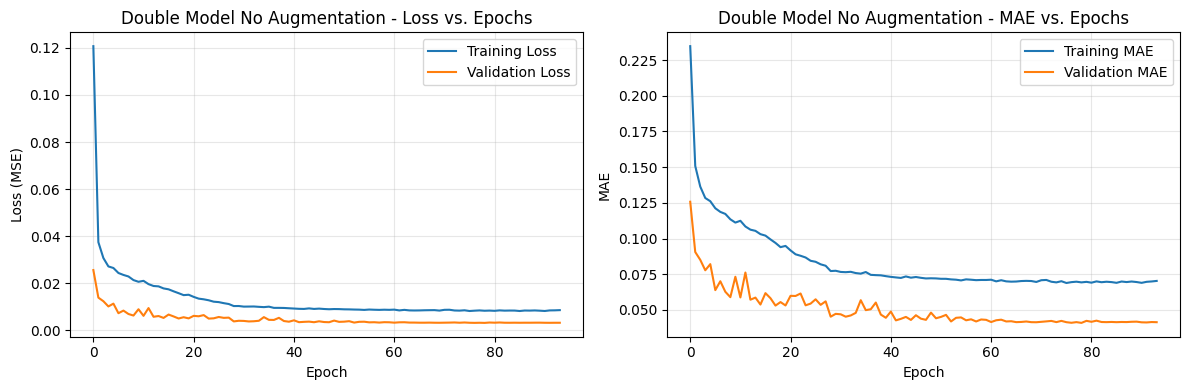


=== Double Model No Augmentation Overfitting Analysis ===
Final Training Loss: 0.0086
Final Validation Loss: 0.0033
Best Validation Loss: 0.0032 (epoch 79)
No significant overfitting detected


In [29]:
# Plot Double Model no Augment
plot_training_history(history_double_shear_no_augment, "Double Model No Augmentation")

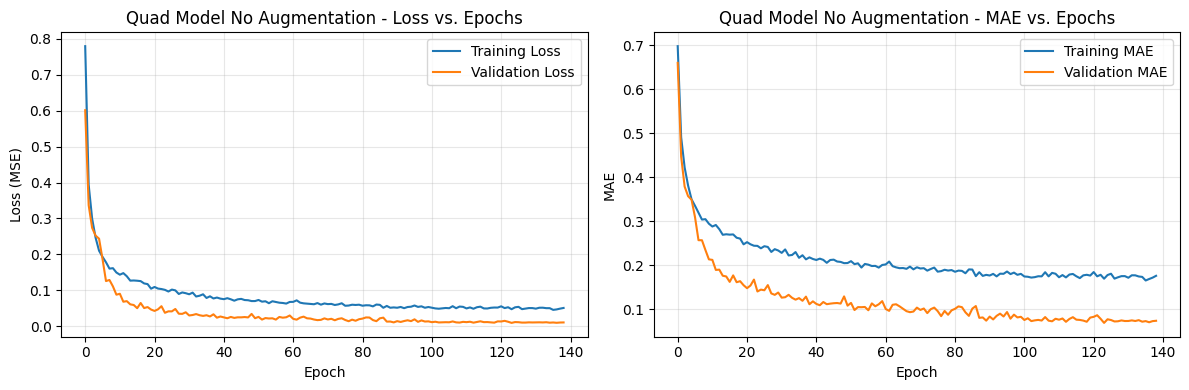


=== Quad Model No Augmentation Overfitting Analysis ===
Final Training Loss: 0.0512
Final Validation Loss: 0.0109
Best Validation Loss: 0.0097 (epoch 124)
No significant overfitting detected


In [30]:
# Plot Double Model no Augment
plot_training_history(history_quad_shear_no_augment, "Quad Model No Augmentation")

In [31]:
'''# Evaluate single model
if len(x_test_single_ellip) > 0:
    single_results = single_shear_model.evaluate(
        x_test_single_ellip, 
        y_test_single_ellip, 
        verbose=1
    )
    print(f"\nSingle Model (trained on shear) → Ellipticity Data:")
    print(f"  Test Loss (MSE): {single_results[0]:.6f}")
    print(f"  Test MAE: {single_results[1]:.6f}")
    print(f"  Number of samples: {len(x_test_single_ellip)}")
else:
    print("No single image ellipticity data to test")


# Evaluate double model
if len(x_test_double_ellip) > 0:
    double_results = double_shear_model.evaluate(
        x_test_double_ellip, 
        y_test_double_ellip, 
        verbose=1
    )
    print(f"\nDouble Model (trained on shear) → Ellipticity Data:")
    print(f"  Test Loss (MSE): {double_results[0]:.6f}")
    print(f"  Test MAE: {double_results[1]:.6f}")
    print(f"  Number of samples: {len(x_test_double_ellip)}")
else:
    print("No double image ellipticity data to test")


# Evaluate quad model
if len(x_test_quad_ellip) > 0:
    quad_results = quad_shear_model.evaluate(
        x_test_quad_ellip, 
        y_test_quad_ellip, 
        verbose=1
    )
    print(f"\nQuad Model (trained on shear) → Ellipticity Data:")
    print(f"  Test Loss (MSE): {quad_results[0]:.6f}")
    print(f"  Test MAE: {quad_results[1]:.6f}")
    print(f"  Number of samples: {len(x_test_quad_ellip)}")
else:
    print("No quad image ellipticity data to test")'''

'# Evaluate single model\nif len(x_test_single_ellip) > 0:\n    single_results = single_shear_model.evaluate(\n        x_test_single_ellip, \n        y_test_single_ellip, \n        verbose=1\n    )\n    print(f"\nSingle Model (trained on shear) → Ellipticity Data:")\n    print(f"  Test Loss (MSE): {single_results[0]:.6f}")\n    print(f"  Test MAE: {single_results[1]:.6f}")\n    print(f"  Number of samples: {len(x_test_single_ellip)}")\nelse:\n    print("No single image ellipticity data to test")\n\n\n# Evaluate double model\nif len(x_test_double_ellip) > 0:\n    double_results = double_shear_model.evaluate(\n        x_test_double_ellip, \n        y_test_double_ellip, \n        verbose=1\n    )\n    print(f"\nDouble Model (trained on shear) → Ellipticity Data:")\n    print(f"  Test Loss (MSE): {double_results[0]:.6f}")\n    print(f"  Test MAE: {double_results[1]:.6f}")\n    print(f"  Number of samples: {len(x_test_double_ellip)}")\nelse:\n    print("No double image ellipticity data to t

##### Ellipticity Only 

In [32]:
'''# Extract data from dictionary for each type 
single_ellip_inputs, single_ellip_outputs, single_ellip_scalers = extract_single_lens_data(single_ellip_data)
double_ellip_inputs, double_ellip_outputs, double_ellip_scalers = extract_double_lens_data(double_ellip_data)
quad_ellip_inputs, quad_ellip_outputs, quad_ellip_scalers = extract_quad_lens_data(quad_ellip_data)'''

'# Extract data from dictionary for each type \nsingle_ellip_inputs, single_ellip_outputs, single_ellip_scalers = extract_single_lens_data(single_ellip_data)\ndouble_ellip_inputs, double_ellip_outputs, double_ellip_scalers = extract_double_lens_data(double_ellip_data)\nquad_ellip_inputs, quad_ellip_outputs, quad_ellip_scalers = extract_quad_lens_data(quad_ellip_data)'

In [33]:
'''print(f"Ellipticity - Singles: {len(single_ellip_inputs)} samples")
print(f"Ellipticity - Doubles: {len(double_ellip_inputs)} samples")
print(f"Ellipticity - Quads: {len(quad_ellip_inputs)} samples")

print(f"Total: {len(single_ellip_inputs) + len(double_ellip_inputs) + len(quad_ellip_inputs)} samples")'''

'print(f"Ellipticity - Singles: {len(single_ellip_inputs)} samples")\nprint(f"Ellipticity - Doubles: {len(double_ellip_inputs)} samples")\nprint(f"Ellipticity - Quads: {len(quad_ellip_inputs)} samples")\n\nprint(f"Total: {len(single_ellip_inputs) + len(double_ellip_inputs) + len(quad_ellip_inputs)} samples")'

##### Both

In [34]:
'''
# Extract data from dictionary for each type 
single_both_inputs, single_both_outputs, single_both_scalers = extract_single_lens_data(single_both_data)
double_both_inputs, double_both_outputs, double_both_scalers = extract_double_lens_data(double_both_data)
quad_both_inputs, quad_both_outputs, quad_both_scalers = extract_quad_lens_data(quad_both_data) '''

'\n# Extract data from dictionary for each type \nsingle_both_inputs, single_both_outputs, single_both_scalers = extract_single_lens_data(single_both_data)\ndouble_both_inputs, double_both_outputs, double_both_scalers = extract_double_lens_data(double_both_data)\nquad_both_inputs, quad_both_outputs, quad_both_scalers = extract_quad_lens_data(quad_both_data) '

In [35]:
'''
print(f"Both - Singles: {len(single_both_inputs)} samples")
print(f"Both - Doubles: {len(double_both_inputs)} samples")
print(f"Both - Quads: {len(quad_both_inputs)} samples")

print(f"Total: {len(single_both_inputs) + len(double_both_inputs) + len(quad_both_inputs)} samples")'''

'\nprint(f"Both - Singles: {len(single_both_inputs)} samples")\nprint(f"Both - Doubles: {len(double_both_inputs)} samples")\nprint(f"Both - Quads: {len(quad_both_inputs)} samples")\n\nprint(f"Total: {len(single_both_inputs) + len(double_both_inputs) + len(quad_both_inputs)} samples")'

In [36]:
data_path_test = repo_root / 'local_gen_test'

In [37]:
vals_shear_test = np.load(data_path_test / 'valShear.npy', allow_pickle=True)
print(len(vals_shear_test))

10


In [38]:
print(len(single_ellip_train) + len(double_ellip_train) + len(quad_ellip_train))


78189


### Histograms

In [39]:
import importlib
import analysis_funcs
importlib.reload(analysis_funcs)

<module 'analysis_funcs' from 'c:\\Users\\satya\\Documents\\GravLensing\\Notebooks\\..\\scripts\\analysis_funcs.py'>

In [40]:
from analysis_funcs import extract_parameters, get_indices_by_image_count
from analysis_funcs import plot_histograms, inverse_transform_predictions, compute_deflection_magnitude
from analysis_funcs import plot_output_histograms_magnitude, plot_residual_histograms, plot_per_image_histograms_magnitude, plot_qq_residuals

In [41]:
# Get indices for ellip‑only (SIE) and both (SIE+shear)
double_ellip, quad_ellip = get_indices_by_image_count(vals_ellip)
double_both, quad_both   = get_indices_by_image_count(vals_both)   # ← use vals_both

print(f"SIE (ellip only): doubles = {len(double_ellip)}, quads = {len(quad_ellip)}")
print(f"SIE+shear (both): doubles = {len(double_both)}, quads = {len(quad_both)}")

# Extract parameters
params_sie_double = extract_parameters(vals_ellip, double_ellip, has_shear=False)
params_sie_quad   = extract_parameters(vals_ellip, quad_ellip,   has_shear=False)
params_both_double = extract_parameters(vals_both,  double_both,  has_shear=True)
params_both_quad   = extract_parameters(vals_both,  quad_both,    has_shear=True)

SIE (ellip only): doubles = 65583, quads = 18528
SIE+shear (both): doubles = 63323, quads = 19993


=== Double Lenses ===


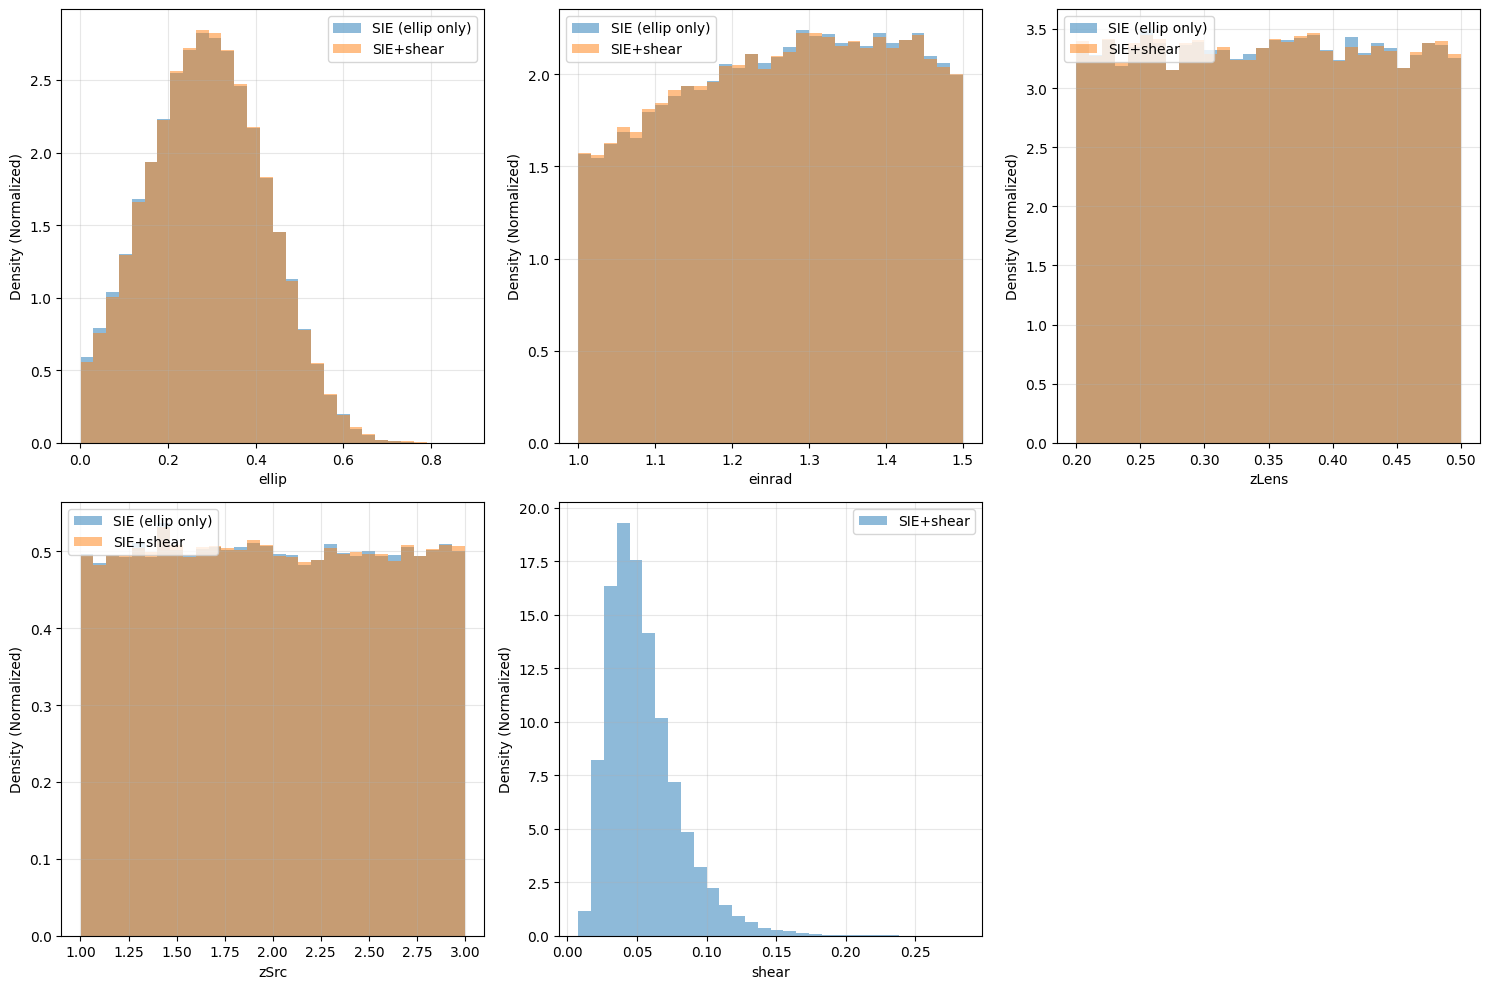

In [42]:
# Compare SIE vs SIE+shear for double lenses
print("=== Double Lenses ===")
plot_histograms([params_sie_double, params_both_double], 
                labels=['SIE (ellip only)', 'SIE+shear'],
                parameters=['ellip', 'einrad', 'zLens', 'zSrc', 'shear'])

=== Quad Lenses ===


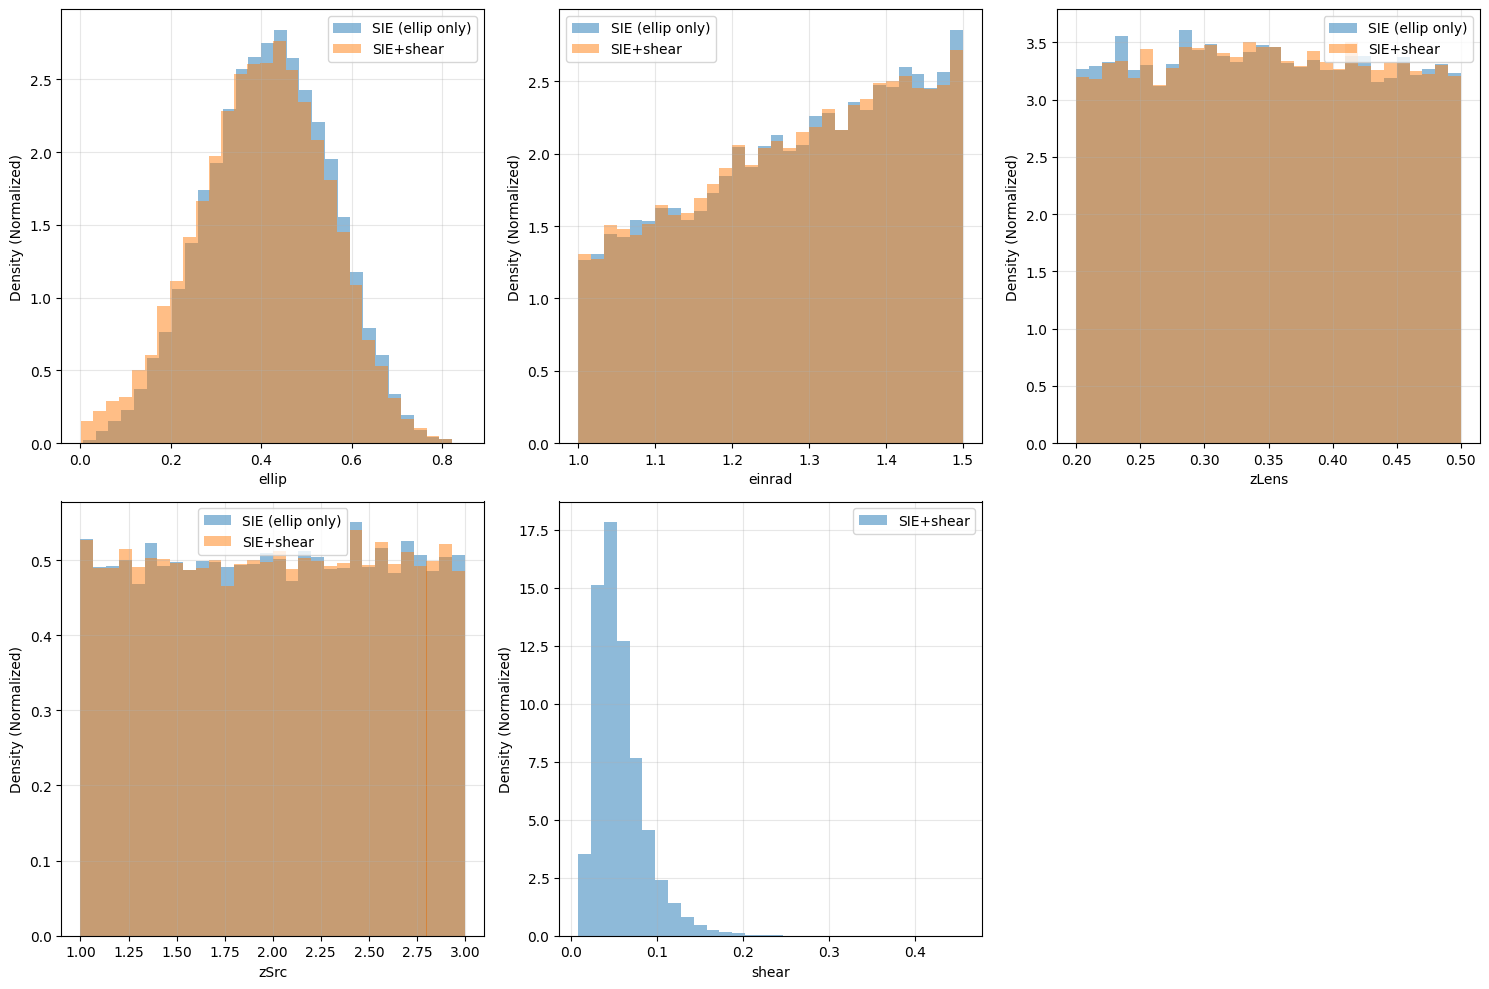

In [43]:
# Compare SIE vs SIE+shear for quad lenses
print("=== Quad Lenses ===")
plot_histograms([params_sie_quad, params_both_quad], 
                labels=['SIE (ellip only)', 'SIE+shear'],
                parameters=['ellip', 'einrad', 'zLens', 'zSrc', 'shear'])

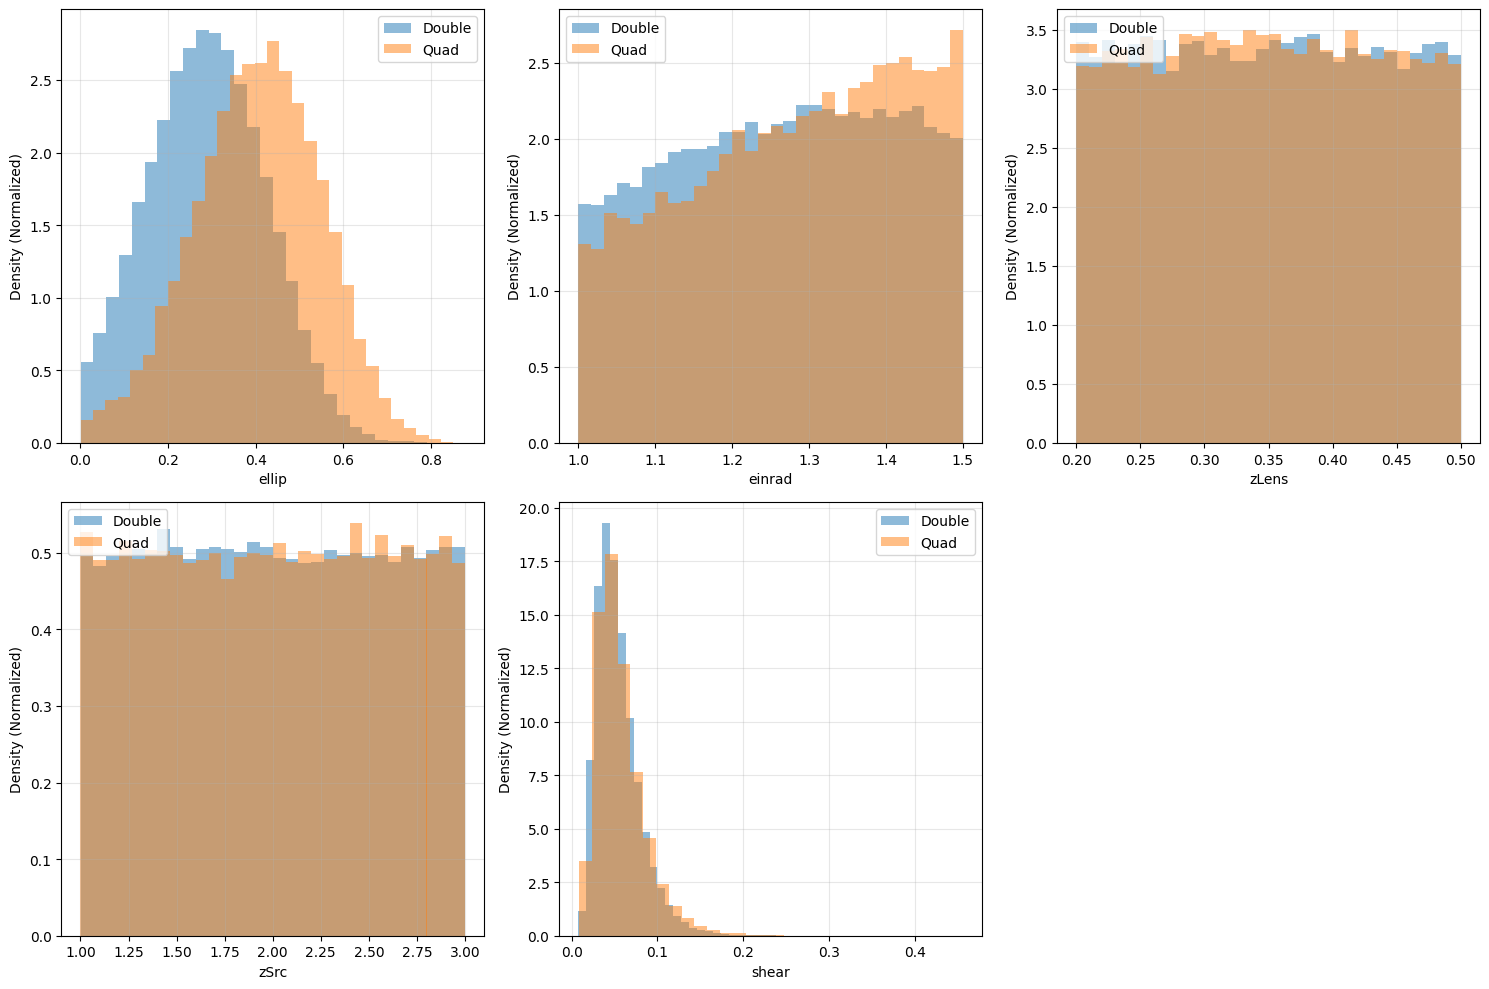

In [44]:
# Compare double vs quad for SIE+shear (both ellipticity and shear)
plot_histograms([params_both_double, params_both_quad],
                labels=['Double', 'Quad'],
                parameters=['ellip', 'einrad', 'zLens', 'zSrc', 'shear'])

In [45]:
# ---- Doubles (no‑augmentation model) ----
if len(x_test_double_shear) > 0:
    y_pred_double_norm = double_shear_model.predict(x_test_double_shear, verbose=0)
    potent_double, deflec_double = inverse_transform_predictions(y_pred_double_norm, double_scalers, n_images=2)
else:
    potent_double, deflec_double = np.array([]), np.array([])

# ---- Quads (no‑augmentation model) ----
if len(x_test_quad_shear) > 0:
    y_pred_quad_norm = quad_shear_model.predict(x_test_quad_shear, verbose=0)
    potent_quad, deflec_quad = inverse_transform_predictions(y_pred_quad_norm, quad_scalers, n_images=4)
else:
    potent_quad, deflec_quad = np.array([]), np.array([])

In [46]:
# -----------------------------------------------------------------------------
# Predictions and inverse transform
# -----------------------------------------------------------------------------

# Inverse transform the true values (using the same function and scalers)
if len(y_test_double_shear) > 0:
    potent_true_double, deflec_true_double = inverse_transform_predictions(
        y_test_double_shear, double_scalers, n_images=2
    )
else:
    potent_true_double = np.array([])
    deflec_true_double = np.array([]).reshape(0, 2, 2)

if len(y_test_quad_shear) > 0:
    potent_true_quad, deflec_true_quad = inverse_transform_predictions(
        y_test_quad_shear, quad_scalers, n_images=4
    )
else:
    potent_true_quad = np.array([])
    deflec_true_quad = np.array([]).reshape(0, 4, 2)

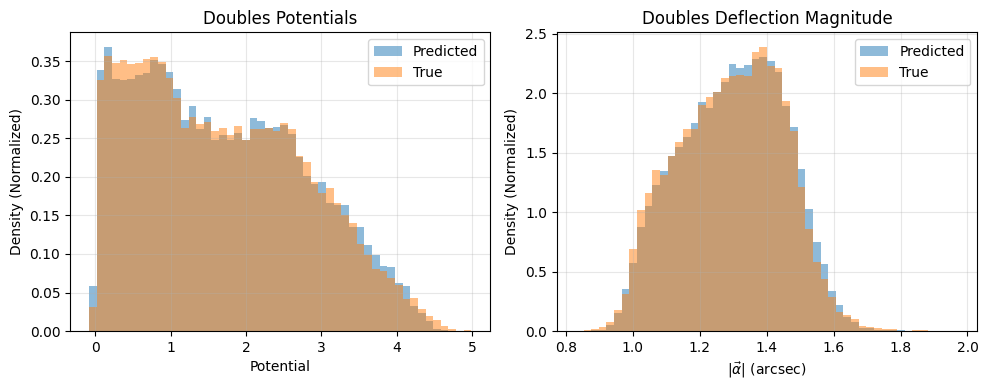

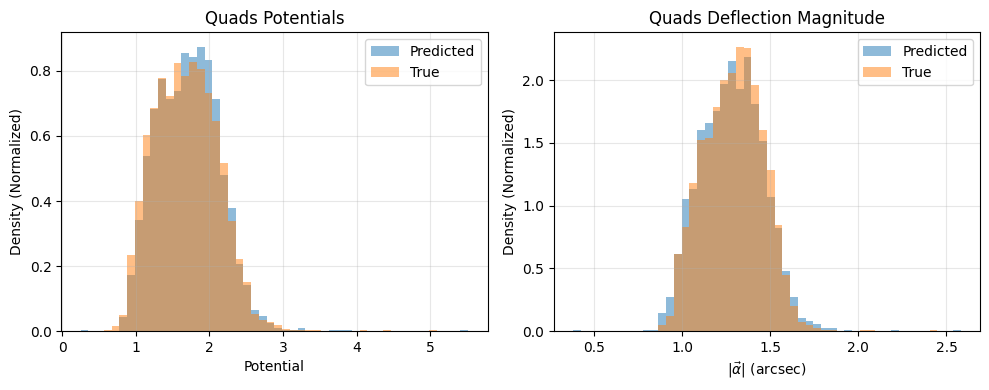

In [47]:
# After inverse transforming predictions and truths:
if potent_double.size > 0:
    plot_output_histograms_magnitude(
        potent_double, potent_true_double,
        deflec_double, deflec_true_double,
        n_images=2, title_prefix="Doubles", bins=50
    )

if potent_quad.size > 0:
    plot_output_histograms_magnitude(
        potent_quad, potent_true_quad,
        deflec_quad, deflec_true_quad,
        n_images=4, title_prefix="Quads", bins=50
    )

### Residual Histogram

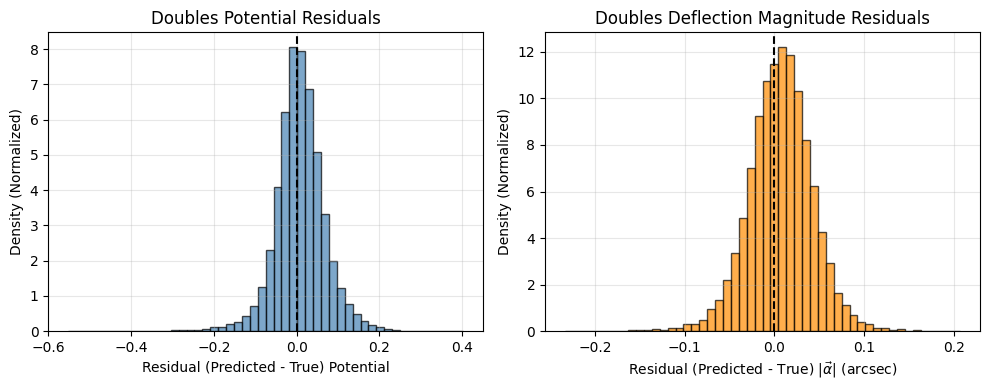


=== Doubles Residual Statistics ===
Potential residuals:  mean = 0.0074, std = 0.0609
Magnitude residuals: mean = 0.0066, std = 0.0355


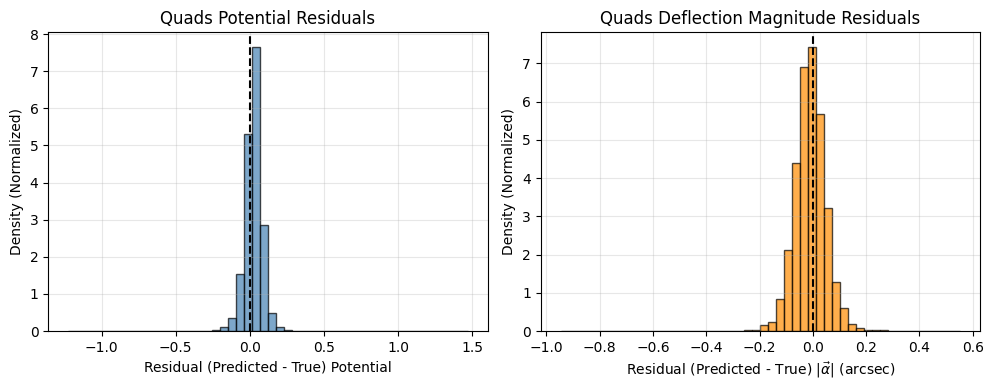


=== Quads Residual Statistics ===
Potential residuals:  mean = 0.0240, std = 0.0687
Magnitude residuals: mean = -0.0089, std = 0.0605


In [48]:
if potent_double.size > 0:
    plot_residual_histograms(potent_double, potent_true_double,
                             deflec_double, deflec_true_double,
                             n_images=2, title_prefix="Doubles", bins=50)

if potent_quad.size > 0:
    plot_residual_histograms(potent_quad, potent_true_quad,
                             deflec_quad, deflec_true_quad,
                             n_images=4, title_prefix="Quads", bins=50)

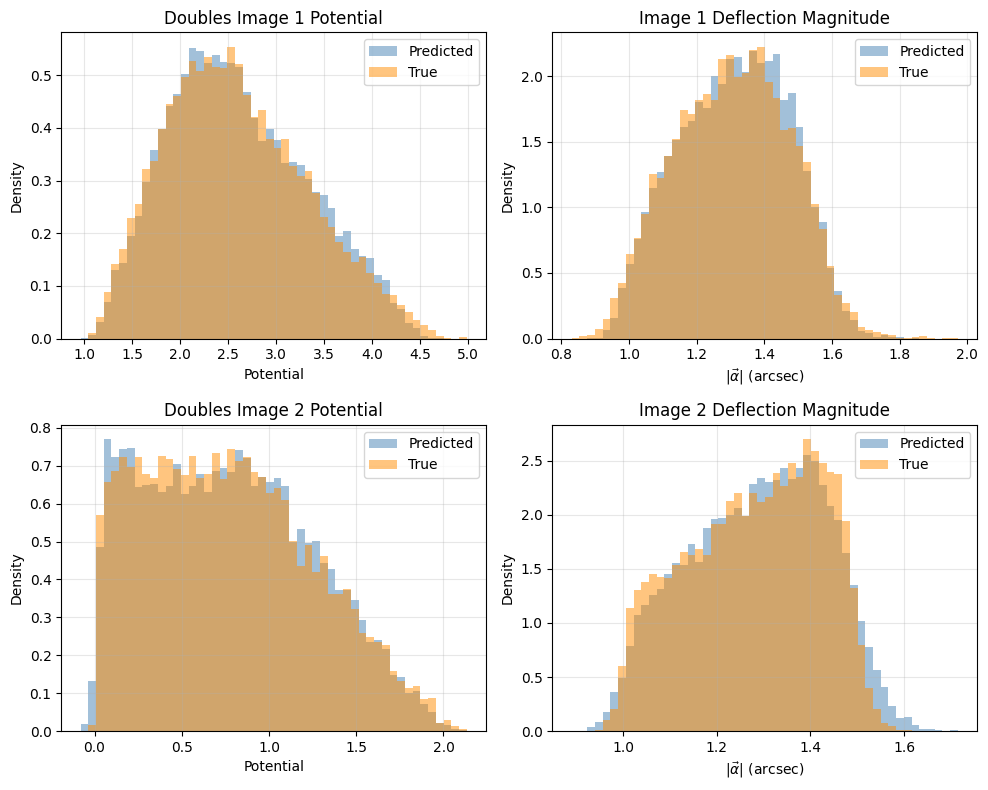

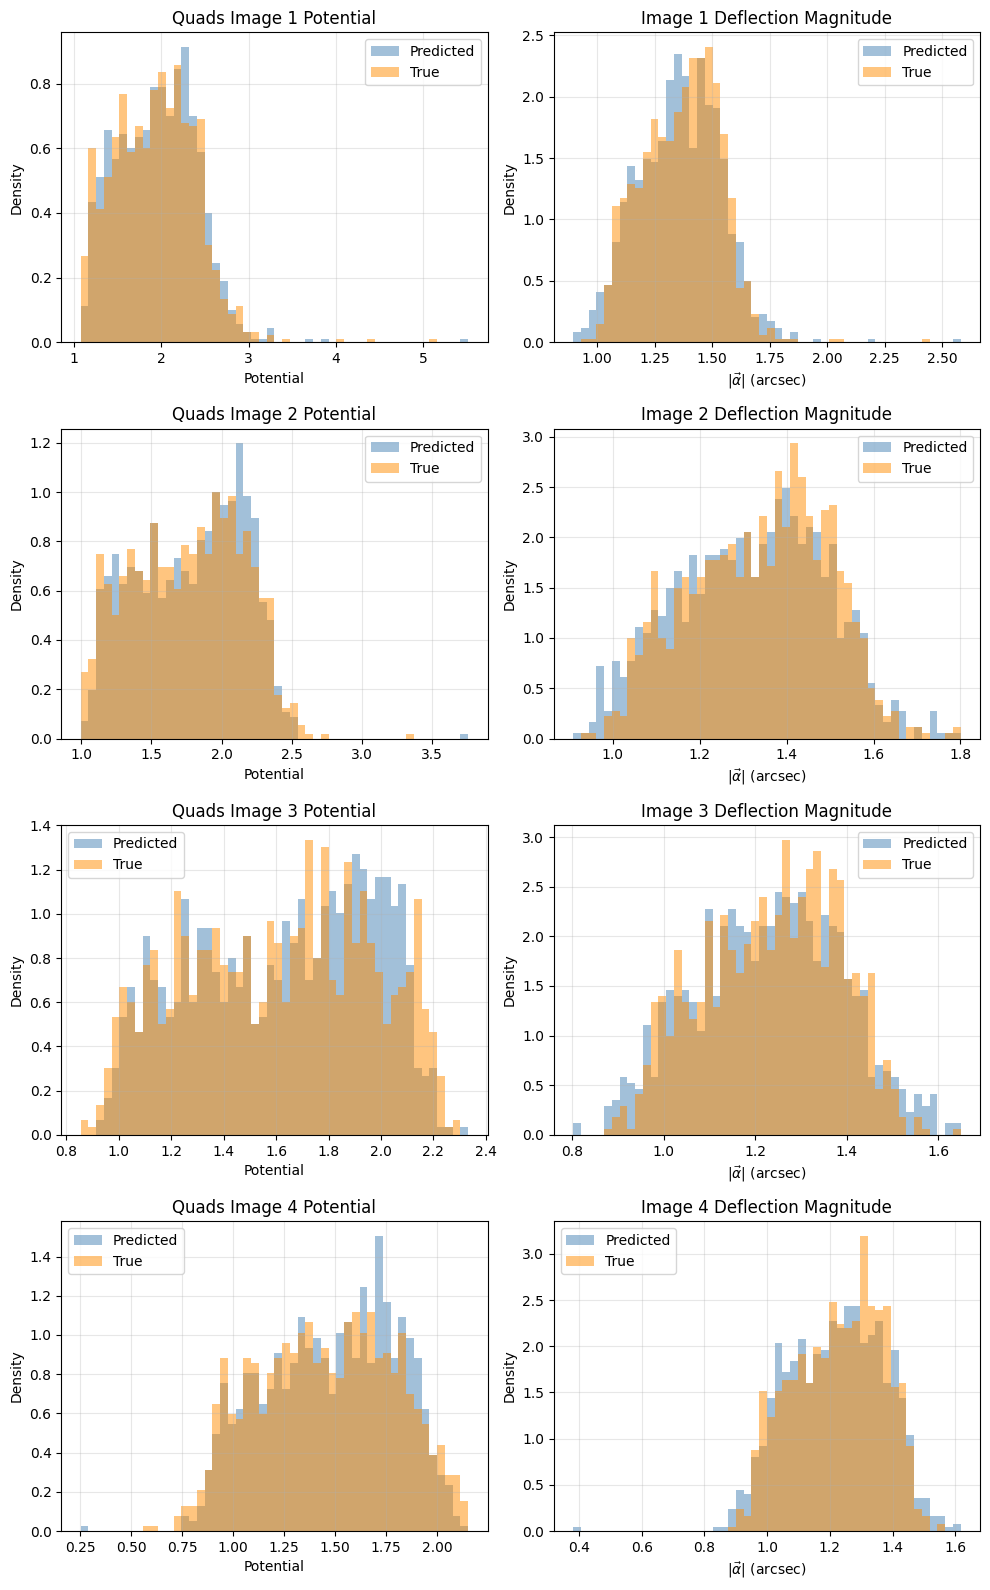

In [49]:
if potent_double.size > 0:
    plot_per_image_histograms_magnitude(potent_double, potent_true_double,
                                        deflec_double, deflec_true_double,
                                        n_images=2, title_prefix="Doubles", bins=50)

if potent_quad.size > 0:
    plot_per_image_histograms_magnitude(potent_quad, potent_true_quad,
                                        deflec_quad, deflec_true_quad,
                                        n_images=4, title_prefix="Quads", bins=50)

In [50]:
from scipy.stats import skew

# Example for doubles potential residuals
resid_pot_double = (potent_double - potent_true_double).flatten()
print(f"Doubles potential skewness: {skew(resid_pot_double):.3f}")

Doubles potential skewness: -0.370


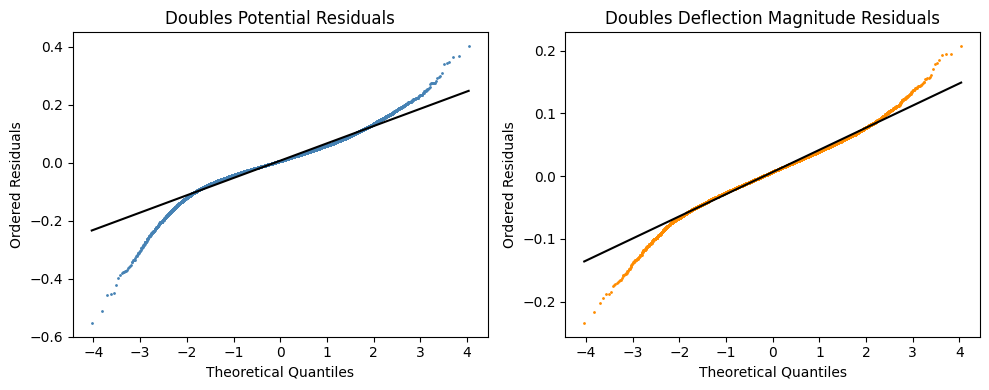

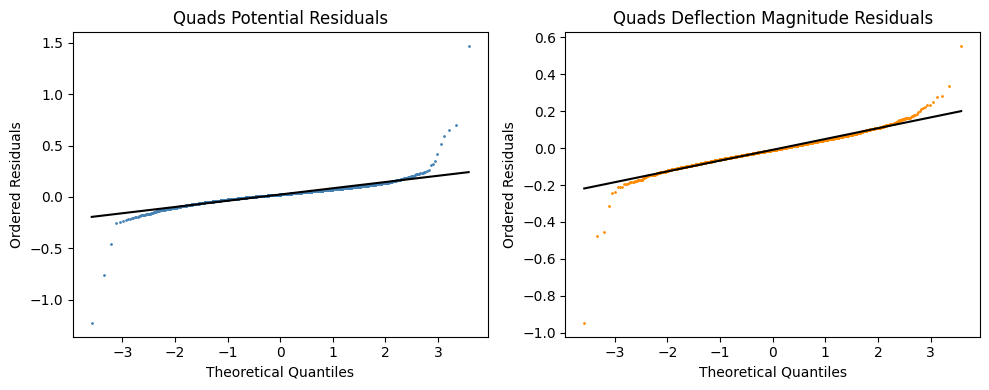

In [51]:
if potent_double.size > 0:
    plot_qq_residuals(potent_double, potent_true_double,
                      deflec_double, deflec_true_double,
                      n_images=2, title_prefix="Doubles")

if potent_quad.size > 0:
    plot_qq_residuals(potent_quad, potent_true_quad,
                      deflec_quad, deflec_true_quad,
                      n_images=4, title_prefix="Quads")

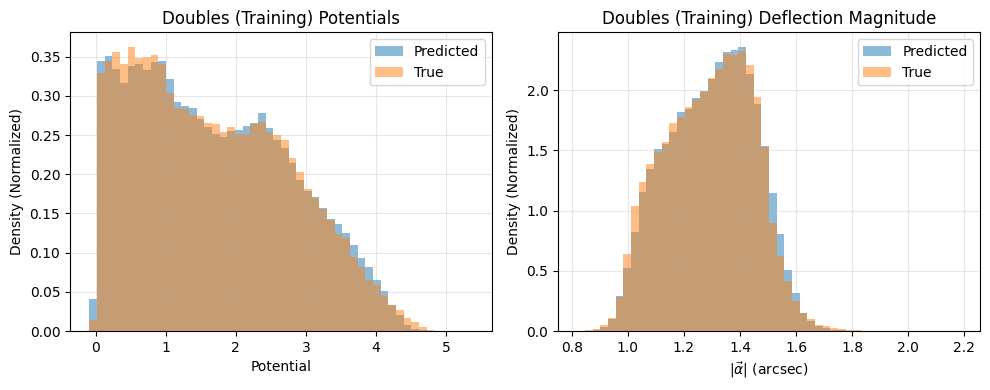

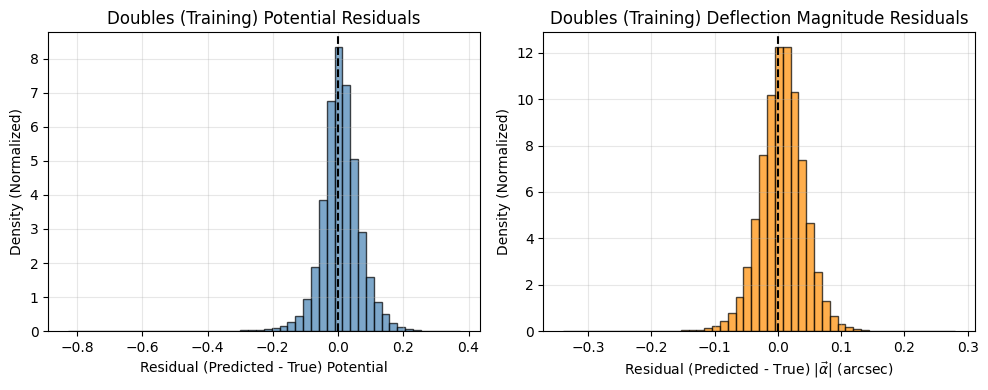


=== Doubles (Training) Residual Statistics ===
Potential residuals:  mean = 0.0082, std = 0.0600
Magnitude residuals: mean = 0.0066, std = 0.0350


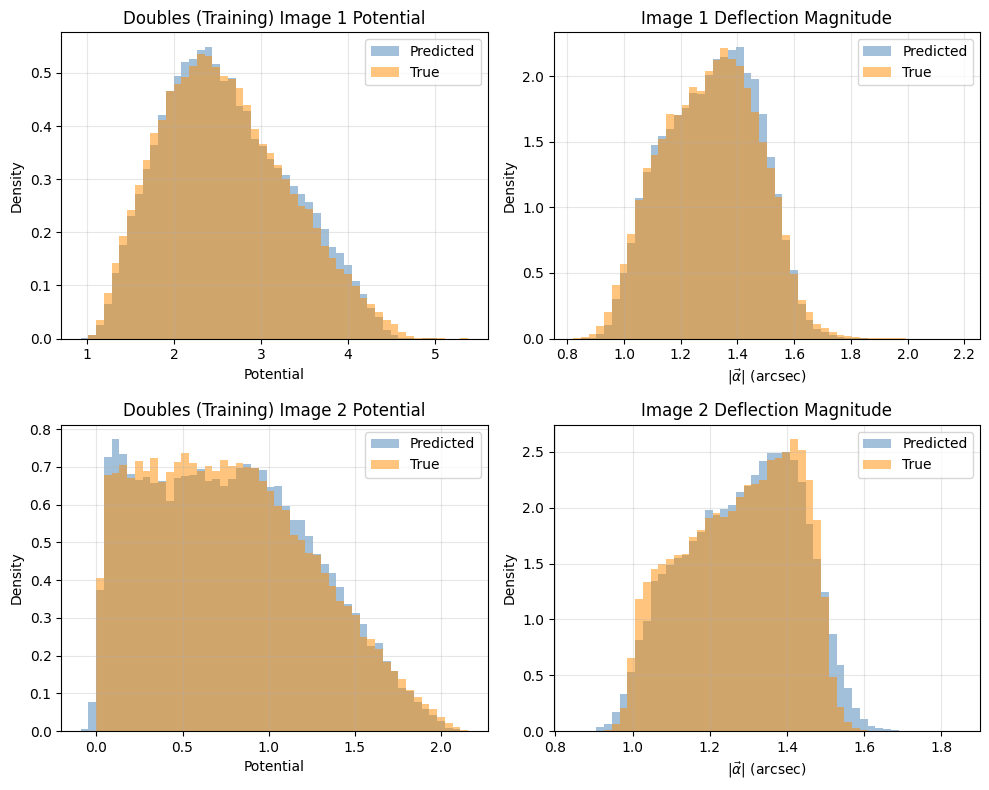

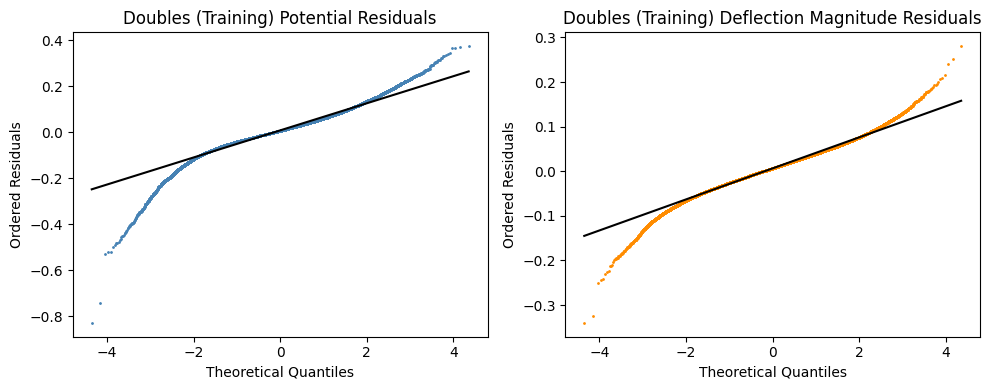

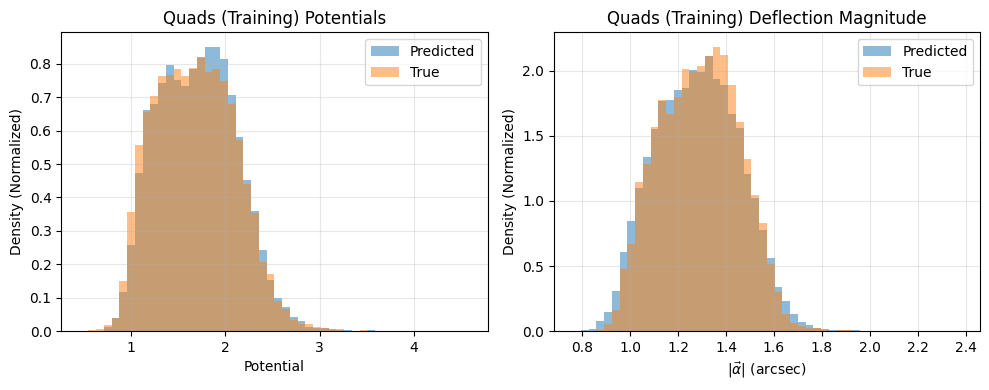

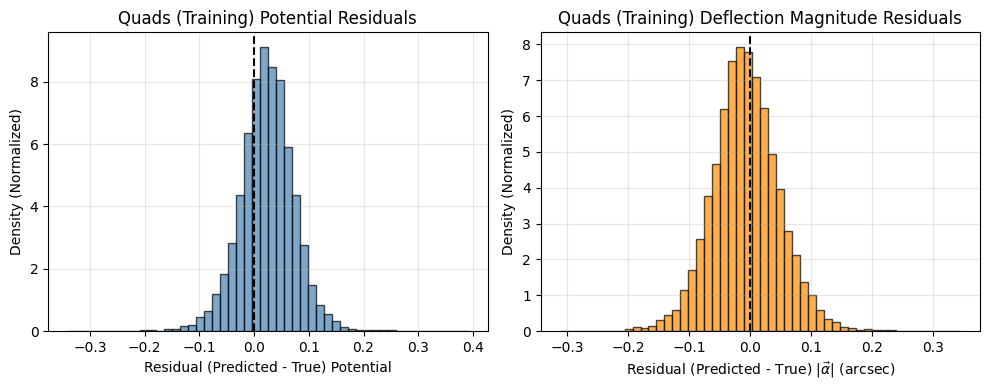


=== Quads (Training) Residual Statistics ===
Potential residuals:  mean = 0.0231, std = 0.0494
Magnitude residuals: mean = -0.0068, std = 0.0550


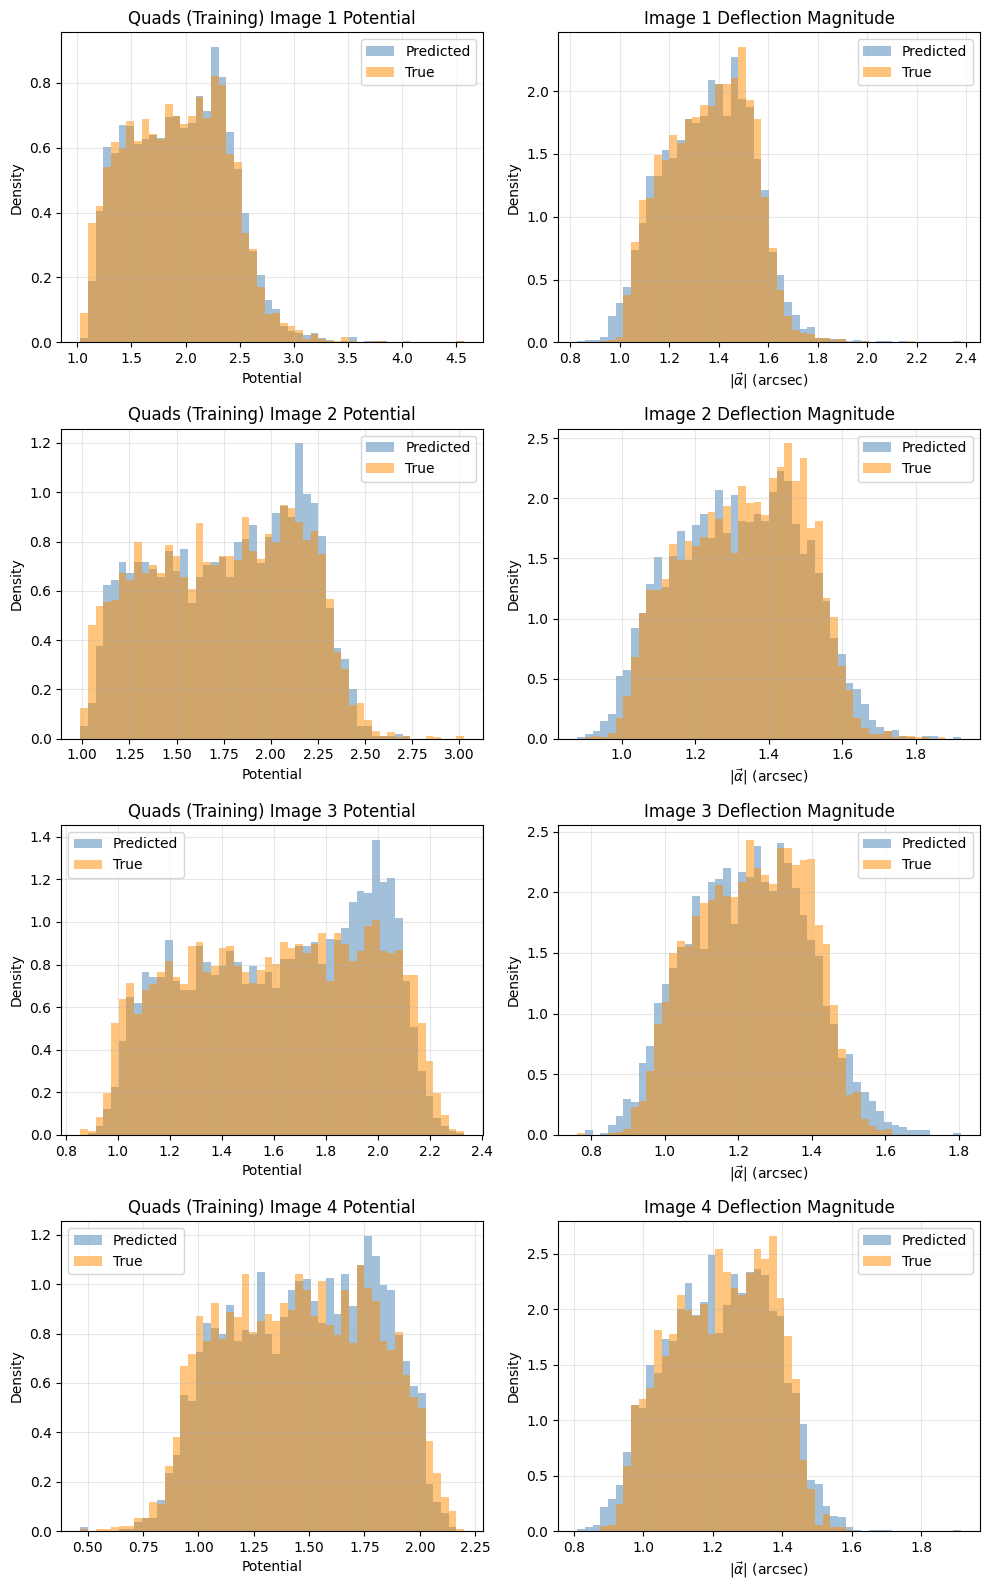

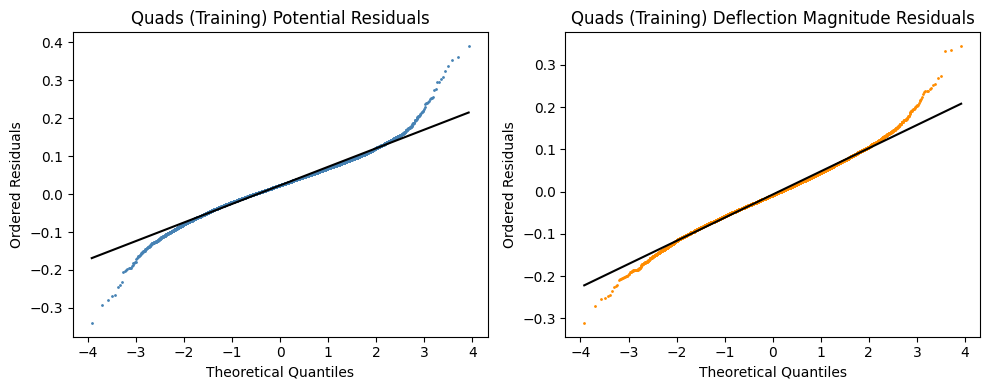

In [52]:
# -----------------------------------------------------------------------------
# Evaluate on TRAINING data (instead of test data)
# -----------------------------------------------------------------------------

# ---- Doubles ----
if len(double_shear_inputs) > 0:
    # Predict on training inputs
    y_pred_double_train_norm = double_shear_model.predict(double_shear_inputs, verbose=0)
    
    # Inverse transform predictions to physical units
    potent_double_train, deflec_double_train = inverse_transform_predictions(
        y_pred_double_train_norm, double_scalers, n_images=2
    )
    # Inverse transform true training outputs (already normalized)
    potent_true_double_train, deflec_true_double_train = inverse_transform_predictions(
        double_shear_outputs, double_scalers, n_images=2
    )
else:
    potent_double_train = np.array([])
    deflec_double_train = np.array([]).reshape(0, 2, 2)
    potent_true_double_train = np.array([])
    deflec_true_double_train = np.array([]).reshape(0, 2, 2)

# ---- Quads ----
if len(quad_shear_inputs) > 0:
    y_pred_quad_train_norm = quad_shear_model.predict(quad_shear_inputs, verbose=0)
    
    potent_quad_train, deflec_quad_train = inverse_transform_predictions(
        y_pred_quad_train_norm, quad_scalers, n_images=4
    )
    potent_true_quad_train, deflec_true_quad_train = inverse_transform_predictions(
        quad_shear_outputs, quad_scalers, n_images=4
    )
else:
    potent_quad_train = np.array([])
    deflec_quad_train = np.array([]).reshape(0, 4, 2)
    potent_true_quad_train = np.array([])
    deflec_true_quad_train = np.array([]).reshape(0, 4, 2)

# Now use existing plotting functions on the training set
if potent_double_train.size > 0:
    plot_output_histograms_magnitude(
        potent_double_train, potent_true_double_train,
        deflec_double_train, deflec_true_double_train,
        n_images=2, title_prefix="Doubles (Training)", bins=50
    )
    plot_residual_histograms(
        potent_double_train, potent_true_double_train,
        deflec_double_train, deflec_true_double_train,
        n_images=2, title_prefix="Doubles (Training)", bins=50
    )
    plot_per_image_histograms_magnitude(
        potent_double_train, potent_true_double_train,
        deflec_double_train, deflec_true_double_train,
        n_images=2, title_prefix="Doubles (Training)", bins=50
    )
    plot_qq_residuals(
        potent_double_train, potent_true_double_train,
        deflec_double_train, deflec_true_double_train,
        n_images=2, title_prefix="Doubles (Training)"
    )

if potent_quad_train.size > 0:
    plot_output_histograms_magnitude(
        potent_quad_train, potent_true_quad_train,
        deflec_quad_train, deflec_true_quad_train,
        n_images=4, title_prefix="Quads (Training)", bins=50
    )
    plot_residual_histograms(
        potent_quad_train, potent_true_quad_train,
        deflec_quad_train, deflec_true_quad_train,
        n_images=4, title_prefix="Quads (Training)", bins=50
    )
    plot_per_image_histograms_magnitude(
        potent_quad_train, potent_true_quad_train,
        deflec_quad_train, deflec_true_quad_train,
        n_images=4, title_prefix="Quads (Training)", bins=50
    )
    plot_qq_residuals(
        potent_quad_train, potent_true_quad_train,
        deflec_quad_train, deflec_true_quad_train,
        n_images=4, title_prefix="Quads (Training)"
    )